In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd

In [2]:
#Importing one of the results:
filepath = '/lustre/storeB/project/fou/hi/foccus/experiments/rollout-benchmark/lr3.5e6-rs3-i0-m3/logs/mlflow/124883160109034645/aa8859acb07a4d23a8b65eb2997064d0/metrics'
""" 
For an overfitting analysis - we focus on the validation and training loss, with epochs on the x-axis. We will be importing the relevant metrics only for simplicity
I believe the metrics are given as: ['ID', 'Vals', 'Steps']
"""
n = ['ID', 'Vals', 'Steps']
epochs_0 = pd.read_csv(f'{filepath}/epoch', header = None, sep = r"\s+", names = n)
val_loss_epoch_0 = pd.read_csv(f'{filepath}/val_multi_dataset_loss_step', header = None, sep = r"\s+", names = n)
train_loss_epoch_0 = pd.read_csv(f'{filepath}/train_multi_dataset_loss_step', header = None , sep = r"\s+", names = n)

In [3]:
epochs_0

,ID,Vals,Steps
0,1791341619449,0.0,99
1,1791342766149,0.0,199
2,1791343913010,0.0,299
3,1791345060344,0.0,399
4,1791346209419,0.0,499
...,...,...,...
523,1791939608710,14.0,50999
524,1791940759906,14.0,51099
525,1791941910196,14.0,51199
526,1791943060374,14.0,51299


In [4]:
val_loss_epoch_0

,ID,Vals,Steps
0,1791381825807,0.006072,0
1,1791381827024,0.006055,1
2,1791381828241,0.006730,2
3,1791381829439,0.006606,3
4,1791381830637,0.006966,4
...,...,...,...
10075,1791932043096,0.006090,10075
10076,1791932044293,0.005960,10076
10077,1791932045494,0.005906,10077
10078,1791932046691,0.006057,10078


In [41]:
resampled_val = val_loss_epoch_0.iloc[99::100].reset_index(drop = True)

In [42]:
resampled_val

,ID,Vals,Steps
0,1791381944653,0.005434,99
1,1791382064669,0.005596,199
2,1791382184666,0.005617,299
3,1791382304661,0.005426,399
4,1791382424680,0.006413,499
...,...,...,...
95,1791931471769,0.005283,9599
96,1791931591774,0.005559,9699
97,1791931711770,0.005574,9799
98,1791931831802,0.007041,9899


In [55]:
interpolated_val = val_loss_epoch_0.set_index('Steps').reindex(train_loss_epoch_0['Steps']).interpolate(method = 'linear').reset_index()

In [56]:
interpolated_val['Steps']
"""
interpolated_reset_index = interpolated_val.reset_index()
interpolated_reset_index['Steps']
"""

"\ninterpolated_reset_index = interpolated_val.reset_index()\ninterpolated_reset_index['Steps']\n"

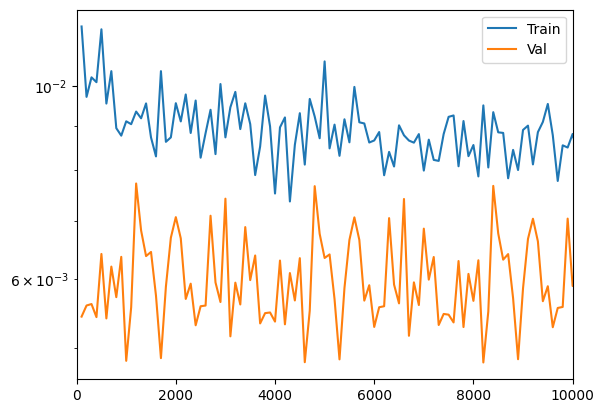

In [70]:
plt.plot(train_loss_epoch_0['Steps'], train_loss_epoch_0['Vals'], label = 'Train')
plt.plot(interpolated_val['Steps'], interpolated_val['Vals'], label = 'Val')
plt.legend()
plt.xlim(0,10000)
plt.yscale('log')


In [10]:
""" 
Kjøre tre timer for alle checkpoints - sjekke om RMSE øker med checkpoint for å vurdere overfitting

eller 

Merge de ulike ID-ene for benchmark uten rollout
"""

' \nKjøre tre timer for alle checkpoints - sjekke om RMSE øker med checkpoint for å vurdere overfitting\n\neller \n\nMerge de ulike ID-ene for benchmark uten rollout\n'

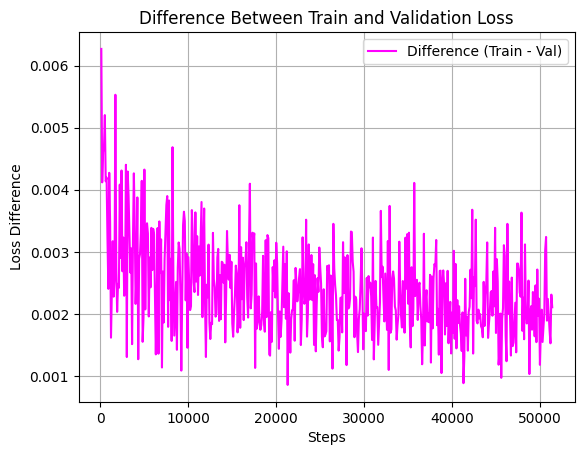

In [66]:
difference = train_loss_epoch_0['Vals'].values - interpolated_val['Vals'].values

plt.plot(train_loss_epoch_0['Steps'], difference, label='Difference (Train - Val)', color='magenta')
plt.xlabel('Steps')
plt.ylabel('Loss Difference')
plt.title('Difference Between Train and Validation Loss')
plt.legend()
plt.grid()
plt.show()

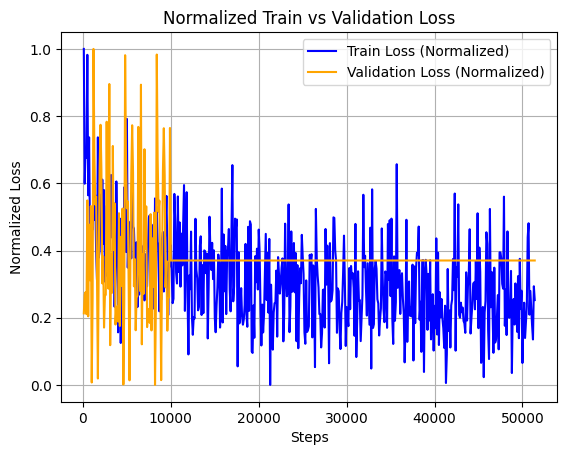

In [67]:
# Normalisering (min-max scaling)
train_loss_epoch_0['Normalized_Vals'] = (train_loss_epoch_0['Vals'] - train_loss_epoch_0['Vals'].min()) / (train_loss_epoch_0['Vals'].max() - train_loss_epoch_0['Vals'].min())
interpolated_val['Normalized_Vals'] = (interpolated_val['Vals'] - interpolated_val['Vals'].min()) / (interpolated_val['Vals'].max() - interpolated_val['Vals'].min())

# Plot de normaliserte verdiene
plt.plot(train_loss_epoch_0['Steps'], train_loss_epoch_0['Normalized_Vals'], label='Train Loss (Normalized)', color='blue')
plt.plot(interpolated_val['Steps'], interpolated_val['Normalized_Vals'], label='Validation Loss (Normalized)', color='orange')
plt.xlabel('Steps')
plt.ylabel('Normalized Loss')
plt.title('Normalized Train vs Validation Loss')
plt.legend()
plt.grid()
plt.show()